# Этап 5. Проверка номинального режима

Код: `make_scene(kind='nominal')` в `rssrl/scenarios.py`, `unsafe_entries` в `rssrl/pilot.py`. Проверки: `tests/test_nominal.py`.

**Номинальный режим** — нарушителя нет. Все фоновые машины тормозят не сильнее 5 м/с² (a_max,brake), то есть продольное допущение RSS соблюдается. Если фильтр сделан правильно, с ним агент не должен попадать в столкновения.

Это проверка до всех экспериментов: если фильтр не справляется даже здесь, столкновения при β > 1 нельзя было бы приписать нарушителю.

**Агенты** (PPO еще не обучен):
- IDLE — держит полосу и целевую скорость, никого не объезжает;
- случайная политика — каждую секунду случайное действие из пяти, в том числе перестроения (seed политики = seed сцены + 1000).

Сцены 0–99, для каждой три варианта: без фильтра, фильтр с задержкой 0, фильтр с задержкой ρ = 0,5 с.

In [1]:
import sys
sys.path.insert(0, '..')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rssrl.pilot import run_grid, plot_episode, unsafe_entries

FIG = Path('..') / 'results' / 'figures'
PILOT = Path('..') / 'results' / 'pilot_05'  # таблицы пилота, в git не идут
PILOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
SEEDS = range(100)
VARIANTS = [(False, 0.0), (True, 0.0), (True, 0.5)]
NAMES = {(False, 0.0): 'без фильтра', (True, 0.0): 'фильтр, задержка 0',
         (True, 0.5): 'фильтр, задержка ρ'}

In [2]:
frames, LOGS = [], {}
for policy in ['idle', 'random']:
    o, logs = run_grid(SEEDS, [1.0], VARIANTS, kind='nominal', policy=policy)
    frames.append(o)
    LOGS[policy] = logs
outcomes = pd.concat(frames, ignore_index=True)
outcomes['вариант'] = [NAMES[(s, d)] for s, d in zip(outcomes['shield'], outcomes['reaction_delay'])]

def per_episode(policy, key):
    log = LOGS[policy][key]
    return {'доля времени фильтр тормозит': log['shield_active'].mean(),
            'мин. скорость, м/с': log['ego_v'].min(),
            'опасных событий от фона': len(unsafe_entries(log))}

extra = pd.DataFrame([per_episode(p, (s, 1.0, sh, d))
                      for p, s, sh, d in zip(outcomes.policy, outcomes.seed, outcomes.shield, outcomes.reaction_delay)])
outcomes = pd.concat([outcomes, extra], axis=1)
outcomes.to_csv(PILOT / 'outcomes.csv', index=False)

summary = outcomes.groupby(['policy', 'вариант'], sort=False).agg(
    эпизодов=('collision', 'size'),
    столкновений=('collision', 'sum'),
    пробег_км=('distance_km', 'mean'),
    фильтр_тормозит=('доля времени фильтр тормозит', 'mean'),
    мин_скорость=('мин. скорость, м/с', 'min'),
    перестроений_запрещено=('lc_blocked', 'sum'),
    перестроений_отменено=('lc_cancelled', 'sum'),
).round(3)
summary

эпизодов  столкновений  пробег_км  фильтр_тормозит  \
policy вариант                                                                  
idle   без фильтра              100            97      0.486            0.000   
       фильтр, задержка 0       100             0      0.878            0.361   
       фильтр, задержка ρ       100             0      0.883            0.349   
random без фильтра              100            94      0.360            0.000   
       фильтр, задержка 0       100             0      0.864            0.178   
       фильтр, задержка ρ       100             0      0.872            0.171   

                           мин_скорость  перестроений_запрещено  \
policy вариант                                                    
idle   без фильтра                9.516                       0   
       фильтр, задержка 0        14.533                       0   
       фильтр, задержка ρ        14.067                       0   
random без фильтра                9.389                     261   
       фильтр, задержка 0        14.570                     788   
       фильтр, задержка ρ        14.333                     867   

                           перестроений_отменено  
policy вариант                                    
idle   без фильтра                             0  
       фильтр, задержка 0                      0  
       фильтр, задержка ρ                      0  
random без фильтра                           418  
       фильтр, задержка 0                     49  
       фильтр, задержка ρ                     46

Как читать таблицу:
- **Без фильтра** агент врезается почти всегда: IDLE едет с целевой скоростью 25 м/с и не тормозит перед более медленной машиной. Без фильтра колонки «запрещено/отменено» показывают, что фильтр *запретил бы*, но сам он не вмешивался.
- **С фильтром** — 0 столкновений в каждом из четырех вариантов (2 политики × 2 задержки), по 100 эпизодов. Все эпизоды доехали до конца времени (40 с).
- **Пробег** с фильтром около 0,87 км за 40 с (≈ 22 м/с): агент не стоит на месте, а едет в потоке. Минимальная скорость с фильтром не ниже 14 м/с.
- **Фильтр тормозит** заметную долю времени — у IDLE около трети. Причина в самом IDLE: он все время пытается разогнаться до 25 м/с и упирается в медленную машину впереди, а фильтр каждый раз его останавливает. Будут ли эти срабатывания «лишними», проверим на этапе 6 контрфактическим прогоном.

## Насколько мала частота столкновений

0 из 100 не значит «ровно ноль». Точная (Клоппера — Пирсона) односторонняя 95 % верхняя граница при 0 столкновений из n эпизодов: 1 − 0,05^(1/n). Считаем отдельно для каждого варианта (объединять разные варианты нельзя).

In [3]:
def upper95(k, n):
    # точная формула только для k = 0; для k > 0 граница тут не нужна
    return 1 - 0.05 ** (1 / n) if k == 0 else np.nan

bound = summary[['эпизодов', 'столкновений']].copy()
bound['верхняя граница 95 %'] = [round(upper95(k, n), 3) for k, n in zip(bound['столкновений'], bound['эпизодов'])]
bound

эпизодов  столкновений  верхняя граница 95 %
policy вариант                                                         
idle   без фильтра              100            97                   NaN
       фильтр, задержка 0       100             0                  0.03
       фильтр, задержка ρ       100             0                  0.03
random без фильтра              100            94                   NaN
       фильтр, задержка 0       100             0                  0.03
       фильтр, задержка ρ       100             0                  0.03

С фильтром при 100 эпизодах можно утверждать только, что частота столкновений в номинальном режиме меньше примерно 3 % на эпизод. Чтобы сузить эту границу до 1 %, понадобилось бы около 300 эпизодов на вариант. Это учтем на этапе 7, когда будем считать объем прогонов.

## Как часто фильтр вмешивается

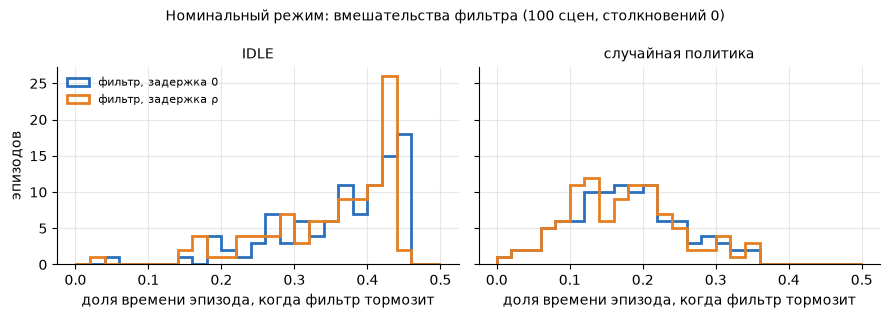

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
colors = {0.0: '#2c6fbb', 0.5: '#e67e22'}
bins = np.linspace(0, 0.5, 26)
for ax, policy, title in zip(axes, ['idle', 'random'], ['IDLE', 'случайная политика']):
    for d in (0.0, 0.5):
        x = outcomes[(outcomes.policy == policy) & outcomes.shield & (outcomes.reaction_delay == d)]
        ax.hist(x['доля времени фильтр тормозит'], bins=bins, histtype='step', linewidth=2,
                color=colors[d], label=NAMES[(True, d)])
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('доля времени эпизода, когда фильтр тормозит')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('эпизодов')
axes[0].legend(fontsize=8, frameon=False)
fig.suptitle('Номинальный режим: вмешательства фильтра (100 сцен, столкновений 0)', fontsize=10)
fig.tight_layout()
fig.savefig(FIG / '05_shield_share.png', dpi=150)

У IDLE фильтр тормозит больше, чем у случайной политики: случайная политика часто сама нажимает SLOWER или уходит в свободную полосу, а IDLE всегда давит на газ. Задержка почти не меняет долю торможения, но меняет его характер: с задержкой 0 фильтр переключается между +3 и −4 м/с² почти каждый шаг («дребезг» на границе d_min), с задержкой ρ — реже и более длинными отрезками.

In [5]:
def switches(log):
    return int((log['shield_active'].astype(int).diff().abs() == 1).sum())

pd.DataFrame({
    NAMES[(True, d)]: [np.mean([switches(LOGS['idle'][(s, 1.0, True, d)]) for s in SEEDS])]
    for d in (0.0, 0.5)
}, index=['IDLE: включений/выключений фильтра за эпизод (среднее)']).round(1)

,"фильтр, задержка 0","фильтр, задержка ρ"
IDLE: включений/выключений фильтра за эпизод (среднее),411.7,74.0


## Фоновые машины нарушают поперечное допущение RSS

Фоновые машины перестраиваются по модели MOBIL, а не по поперечной RSS, и сдвигаются вбок быстро (до ~5 м/с). Иногда машина впереди агента начинает сдвигаться к нему, когда продольно она уже ближе d_min: в его полосу или в соседнюю. По RSS это опасная ситуация, и создает ее фоновая машина. Ищем такие моменты: впереди появилась новая опасная машина (продольно и поперечно ближе d_min), а сам агент последние 3 с полосу не менял (`unsafe_entries`). Первые 3 с эпизода не считаем: highway-env расставляет машины на старте случайно, без учета d_min (сколько эпизодов начинаются с зазора меньше d_min — ниже). У IDLE агент полосу не меняет никогда, поэтому для него подсчет точный.

In [6]:
ue = outcomes[outcomes.shield].groupby(['policy', 'вариант'], sort=False).agg(
    эпизодов_с_событием=('опасных событий от фона', lambda x: int((x > 0).sum())),
    событий_всего=('опасных событий от фона', 'sum'),
)
ue

эпизодов_с_событием  событий_всего
policy вариант                                               
idle   фильтр, задержка 0                    8             10
       фильтр, задержка ρ                    7             11
random фильтр, задержка 0                   52             85
       фильтр, задержка ρ                   49             80

In [7]:
start_unsafe = np.mean([
    (LOGS['idle'][(s, 1.0, True, 0.0)]['gap'].iloc[0] < LOGS['idle'][(s, 1.0, True, 0.0)]['d_min'].iloc[0])
    for s in SEEDS])
print(f'Эпизодов, где на первом шаге зазор до машины впереди меньше d_min: {start_unsafe:.0%}')

Эпизодов, где на первом шаге зазор до машины впереди меньше d_min: 36%


,seed,t,зазор / d_min
0,0,3.33,0.97
1,11,6.33,0.54
2,29,3.47,0.51
3,40,35.13,-0.07
4,44,5.00,0.03
5,63,3.07,0.46
6,68,4.07,0.56
7,77,3.07,0.07
8,77,4.33,0.30
9,77,5.20,0.11


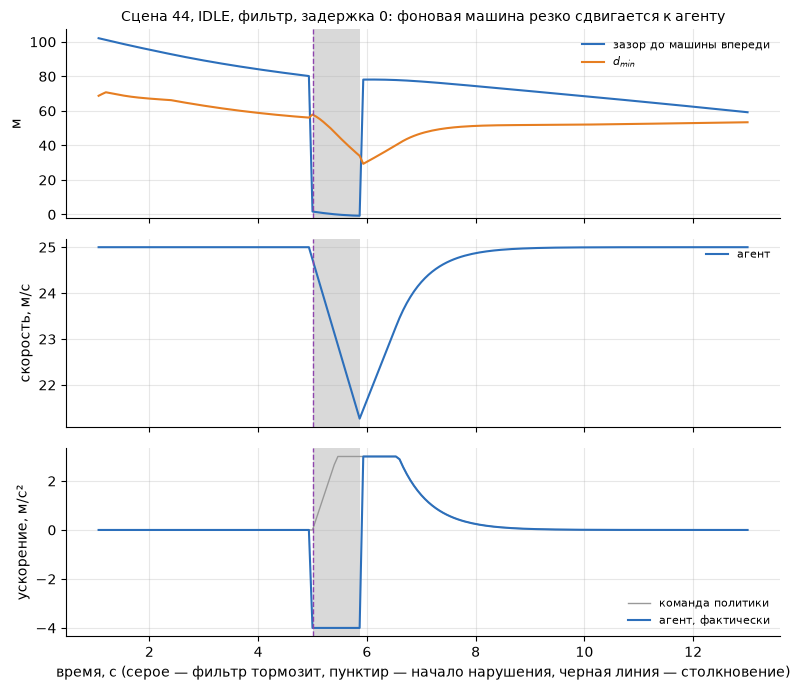

In [8]:
rows = []
for s in SEEDS:
    ev = unsafe_entries(LOGS['idle'][(s, 1.0, True, 0.0)])
    rows += [(s, r.t, r.ratio) for r in ev.itertuples()]
ev_idle = pd.DataFrame(rows, columns=['seed', 't', 'зазор / d_min'])
# пример: самое близкое событие с положительным зазором
seed_ex, t_ex = ev_idle[ev_idle['зазор / d_min'] > 0].sort_values('зазор / d_min').iloc[0][['seed', 't']]
seed_ex = int(seed_ex)
log = LOGS['idle'][(seed_ex, 1.0, True, 0.0)]
win = log[(log.t > t_ex - 4) & (log.t < t_ex + 8)]
axes = plot_episode(win, f'Сцена {seed_ex}, IDLE, фильтр, задержка 0: '
                    f'фоновая машина резко сдвигается к агенту')
for ax in axes:
    ax.axvline(t_ex, color='#8e44ad', linewidth=1, linestyle='--')
axes[0].set_ylim(-2, None)
plt.gcf().tight_layout()
plt.gcf().savefig(FIG / '05_background_cutin.png', dpi=150)
ev_idle.round(2)

На графике (фиолетовый штрих — момент события) зазор скачком падает почти до нуля: машина в 6 м впереди, через полосу от агента, начала перестраиваться в соседнюю с ним полосу и быстро сдвигалась к нему. Поперечный зазор стал меньше поперечного d_min, и фильтр затормозил. Когда машина закончила перестроение в соседней полосе, поперечная опасность исчезла, и критичной снова стала прежняя машина впереди (зазор ~78 м). Столкновения не было.

Заметим: по строгой RSS в такой ситуации (продольно машины уже были ближе d_min, когда возникла поперечная опасность) правильный ответ — поперечный, продольное торможение не обязательно. Наш фильтр тормозит всегда — это осторожнее, чем требует RSS, и даст часть «лишних» срабатываний (этап 6).

Это важно для методики. «Номинальный режим» номинален по продольному допущению (торможение ≤ 5 м/с²), но фон иногда нарушает поперечное. Столкновений это в пилоте не вызвало: въезжающие машины едут почти с той же скоростью, что и агент. Варианты: (а) оставить как есть и описать в статье как свойство фона, одинаковое для всех β и γ; (б) запретить фону перестраиваться ближе d_min к агенту. Вопрос для письма преподавателю.

## Выводы этапа 5

1. В номинальном режиме с фильтром столкновений нет: 0 из 100 для каждой из двух политик и каждой из двух задержек. Верхняя 95 % граница частоты — около 3 % на вариант. Без фильтра столкновений 94–97 из 100.
2. Фильтр не «покупает» безопасность остановкой: агент едет ≈ 22 м/с, минимальная скорость не ниже 14 м/с, все эпизоды доходят до конца времени. Ускорения агента не выходят за [−5; 3] м/с².
3. Фильтр тормозит заметную долю времени (у IDLE около трети). Это следствие поведения IDLE. Нужна ли каждая такая реакция, покажет контрфактическая проверка на этапе 6.
4. Фоновые машины иногда резко сдвигаются к агенту, когда продольно уже ближе d_min (MOBIL не знает RSS). Это одинаково для всех уровней β и γ, но об этом нужно написать и спросить преподавателя.
5. Наш фильтр на любую опасность впереди отвечает продольным торможением. Строгая RSS в части случаев требует только поперечного ответа, так что фильтр осторожнее RSS. Это надо указать в статье как упрощение.
6. highway-env расставляет машины на старте без учета d_min (около трети эпизодов начинаются в опасной ситуации). Нарушения начинаются не раньше 3 с, но об этом тоже стоит написать.